# CNN ResNet50 — Clasificación de Severidad Lumbar
## RSNA 2024 Lumbar Spine Degenerative Classification

**Enfoque:** Recortes 2D de imagen DICOM centrados en (x, y) de cada hallazgo → ResNet50 preentrenada → 3 clases de severidad  
**Semilla:** 42 · **Split:** 35/35/30 por `study_id` · **GPU requerida**

## 0. Instalación e importaciones

In [1]:
# Instalar pydicom si no está disponible
import subprocess, sys
try:
    import pydicom
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pydicom"])
    import pydicom

import os, json, time, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import torchvision.models as models
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, recall_score,
    cohen_kappa_score, log_loss, confusion_matrix
)

# ── Detección automática de Paths (Kaggle) ──
# 1. Buscar directorio con las imágenes DICOM (train_images)
posibles_img = [
    Path("/kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification"),
    Path("/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification"),
]
INPUT = None
for p in posibles_img:
    if (p / "train_images").exists():
        INPUT = p
        break

if INPUT is None:
    for root, dirs, files in os.walk("/kaggle/input"):
        if "train_images" in dirs:
            INPUT = Path(root)
            break
        if "train_images" in dirs:
            dirs.remove("train_images")

# 2. Buscar directorio con los CSVs (train.csv) en cualquier dataset montado
CSV_DIR = None
if INPUT and (INPUT / "train.csv").exists():
    CSV_DIR = INPUT
else:
    for root, dirs, files in os.walk("/kaggle/input"):
        if "train_images" in dirs:
            dirs.remove("train_images")  # evitar entrar a los 35GB
        if "train.csv" in files:
            CSV_DIR = Path(root)
            break

if CSV_DIR is None and Path("/kaggle/working/train.csv").exists():
    CSV_DIR = Path("/kaggle/working")

print(f"Directorio Imágenes (INPUT): {INPUT}")
print(f"Directorio CSVs     (CSV_DIR): {CSV_DIR}")

WORK   = Path("/kaggle/working")
MODELS = WORK / "models"
FIG    = WORK / "figures"
CROPS  = WORK / "crops"
for d in [MODELS, FIG, CROPS]: d.mkdir(exist_ok=True)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ── Paleta semántica consistente ──
PAL = {"Normal/Mild": "#4C72B0", "Moderate": "#DD8452", "Severe": "#8B0000"}
CLASS_ORDER = ["Normal/Mild", "Moderate", "Severe"]
SEV_MAP     = {"Normal/Mild": 0, "Moderate": 1, "Severe": 2}
INV_SEV     = {0: "Normal/Mild", 1: "Moderate", 2: "Severe"}
plt.rcParams.update({"figure.dpi": 150, "font.size": 11})
print("Configuración OK")


Directorio Imágenes (INPUT): /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification
Directorio CSVs     (CSV_DIR): /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification
Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB
Configuración OK


## 1. Carga de datos y función de normalización

In [2]:
# ── Carga de datos desde CSV_DIR (con fallback a INPUT) ──
csv_path = CSV_DIR if CSV_DIR is not None else INPUT

train  = pd.read_csv(csv_path / "train.csv")
coords = pd.read_csv(csv_path / "train_label_coordinates.csv" if (csv_path / "train_label_coordinates.csv").exists() else INPUT / "train_label_coordinates.csv")
series = pd.read_csv(csv_path / "train_series_descriptions.csv" if (csv_path / "train_series_descriptions.csv").exists() else INPUT / "train_series_descriptions.csv")

print(f"train.csv:                   {train.shape}")
print(f"train_label_coordinates.csv: {coords.shape}")
print(f"train_series_descriptions.csv:{series.shape}")

# ── Mapeo condition → prefijo de columna ──
COND_MAP = {
    "Spinal Canal Stenosis":          "spinal_canal_stenosis",
    "Left Neural Foraminal Narrowing":"left_neural_foraminal_narrowing",
    "Right Neural Foraminal Narrowing":"right_neural_foraminal_narrowing",
    "Left Subarticular Stenosis":     "left_subarticular_stenosis",
    "Right Subarticular Stenosis":    "right_subarticular_stenosis",
}

def normalizar(condition, level):
    return f"{COND_MAP[condition]}_{level.lower().replace('/', '_')}"

# ── Merge y agregar severidad ──
df = coords.merge(series, on=["study_id", "series_id"], how="left")
train_idx = train.set_index("study_id")

def buscar_sev(row):
    try:
        return train_idx.loc[row["study_id"], normalizar(row["condition"], row["level"])]
    except:
        return np.nan

df["severidad"] = df.apply(buscar_sev, axis=1)
df["severidad_num"] = df["severidad"].map(SEV_MAP)
df_clean = df.dropna(subset=["severidad"]).copy().reset_index(drop=True)

print(f"\nMuestras totales (con etiqueta): {len(df_clean):,}")
for cls in CLASS_ORDER:
    n = (df_clean["severidad"] == cls).sum()
    print(f"  {cls:18s}: {n:6,} ({n/len(df_clean)*100:.1f}%)")


train.csv:                   (1975, 26)
train_label_coordinates.csv: (48692, 7)
train_series_descriptions.csv:(6294, 3)

Muestras totales (con etiqueta): 48,657
  Normal/Mild       : 37,626 (77.3%)
  Moderate          :  7,950 (16.3%)
  Severe            :  3,081 (6.3%)


## 2. Split por `study_id` — 35 / 35 / 30 (semilla 42)

In [3]:
from sklearn.model_selection import GroupShuffleSplit

study_df = (
    df_clean.groupby("study_id")["severidad"]
    .apply(lambda s: "has_severe" if "Severe" in s.values else "no_severe")
    .reset_index().rename(columns={"severidad": "strat"})
)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
idx_trval, idx_test = next(gss1.split(study_df, groups=study_df["study_id"]))
study_trval = study_df.iloc[idx_trval]
study_test  = study_df.iloc[idx_test]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
idx_tr, idx_val = next(gss2.split(study_trval, groups=study_trval["study_id"]))
study_train = study_trval.iloc[idx_tr]
study_val   = study_trval.iloc[idx_val]

split_map = {}
for sid in study_train["study_id"]: split_map[sid] = "train"
for sid in study_val["study_id"]:   split_map[sid] = "val"
for sid in study_test["study_id"]:  split_map[sid] = "test"

df_clean["split"] = df_clean["study_id"].map(split_map)

for s in ["train", "val", "test"]:
    sub = df_clean[df_clean["split"] == s]
    counts = sub["severidad"].value_counts()
    print(f"{s:6s}: {len(sub):6,} muestras — "
          f"N/M={counts.get('Normal/Mild',0):,} "
          f"Mod={counts.get('Moderate',0):,} "
          f"Sev={counts.get('Severe',0):,}")

pd.DataFrame([{"study_id": sid, "split": sp} for sid, sp in split_map.items()]
             ).to_csv(WORK / "splits.csv", index=False)
print("\n splits.csv guardado")


train : 17,006 muestras — N/M=13,218 Mod=2,723 Sev=1,065
val   : 17,039 muestras — N/M=13,150 Mod=2,802 Sev=1,087
test  : 14,612 muestras — N/M=11,258 Mod=2,425 Sev=929

 splits.csv guardado


## 3. Lectura de DICOM y generación de recortes

Cada muestra es un recorte 96×96 px centrado en la coordenada `(x, y)` del hallazgo, normalizado a [0, 1] recortando los percentiles 1-99.

Imagen completa: (640, 640) — rango [0.000, 1.000]
Recorte: (96, 96)


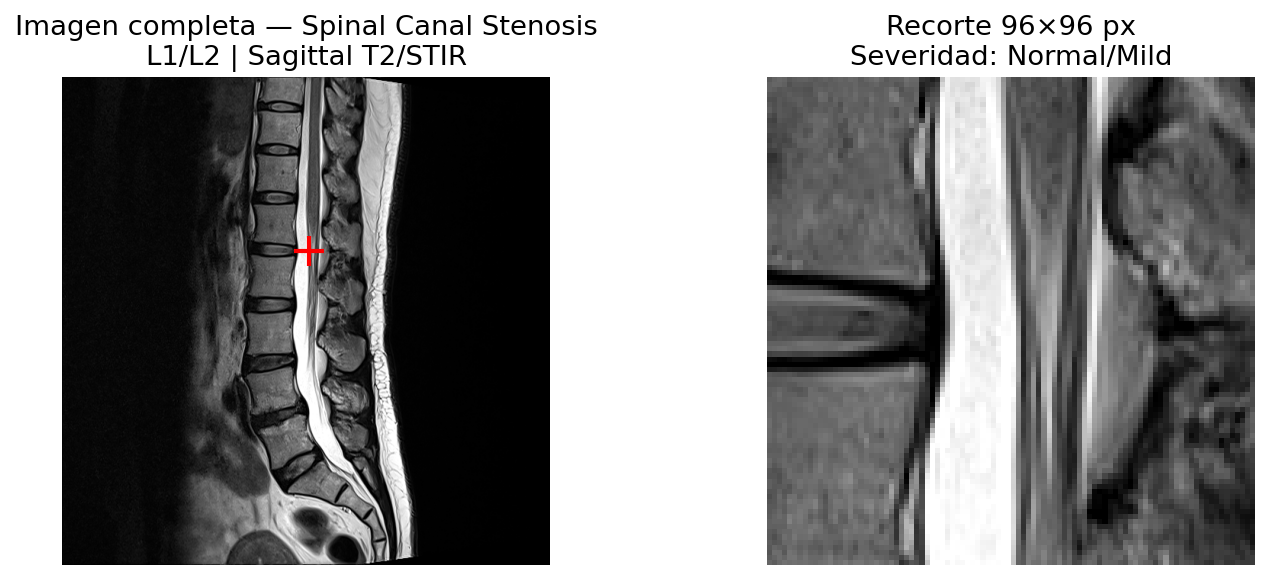

Verificación OK


In [4]:
CROP_SIZE = 96  # px — ventana cuadrada alrededor de (x, y)

def leer_dicom_como_array(study_id, series_id, instance_number):
    """Lee un archivo DICOM y devuelve el array de píxeles normalizado [0,1]."""
    path = INPUT / "train_images" / str(study_id) / str(series_id) / f"{instance_number}.dcm"
    dcm = pydicom.dcmread(str(path), stop_before_pixels=False)
    img = dcm.pixel_array.astype(np.float32)
    # Normalizar: percentil 1-99 para robustez ante outliers de intensidad
    p1, p99 = np.percentile(img, [1, 99])
    img = np.clip(img, p1, p99)
    img = (img - p1) / (p99 - p1 + 1e-7)
    return img  # float32 en [0, 1]

def recortar(img, cx, cy, size=CROP_SIZE):
    """
    Recorta una ventana cuadrada centrada en (cx, cy).
    Si el recorte se sale del borde, rellena con ceros (padding).
    """
    H, W = img.shape
    half = size // 2
    x1, x2 = int(cx) - half, int(cx) + half
    y1, y2 = int(cy) - half, int(cy) + half

    # Calcular zonas válidas
    sx1, sx2 = max(0, x1), min(W, x2)
    sy1, sy2 = max(0, y1), min(H, y2)
    # Posición en el recorte
    dx1 = sx1 - x1
    dy1 = sy1 - y1

    crop = np.zeros((size, size), dtype=np.float32)
    crop[dy1:dy1+(sy2-sy1), dx1:dx1+(sx2-sx1)] = img[sy1:sy2, sx1:sx2]
    return crop

def probar_lectura():
    """Verifica que se puede leer un DICOM y recortar correctamente."""
    row = df_clean.iloc[0]
    img = leer_dicom_como_array(row.study_id, row.series_id, row.instance_number)
    crop = recortar(img, row.x, row.y)
    print(f"Imagen completa: {img.shape} — rango [{img.min():.3f}, {img.max():.3f}]")
    print(f"Recorte: {crop.shape}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    ax1.imshow(img, cmap="gray")
    ax1.plot(row.x, row.y, "r+", markersize=14, markeredgewidth=2)
    ax1.set_title(f"Imagen completa — {row.condition}\n{row.level} | {row.series_description}")
    ax2.imshow(crop, cmap="gray")
    ax2.set_title(f"Recorte {CROP_SIZE}×{CROP_SIZE} px\nSeveridad: {row.severidad}")
    for ax in [ax1, ax2]: ax.axis("off")
    plt.tight_layout()
    plt.savefig(FIG / "verificacion_dicom_recorte.png", dpi=150)
    plt.show()
    print("Verificación OK")

probar_lectura()


## 4. Dataset y DataLoaders de PyTorch

In [5]:
# Codificación de condition y level para el modelo
COND_ENCODE = {c: i for i, c in enumerate(sorted(df_clean["condition"].unique()))}
LEVEL_ENCODE = {"L1/L2": 0, "L2/L3": 1, "L3/L4": 2, "L4/L5": 3, "L5/S1": 4}

# Transformaciones de aumentación (solo en train)
transform_train = T.Compose([
    T.ToPILImage(),
    T.Resize((224, 224)),
    T.RandomRotation(degrees=10),           # rotación leve — no rompe anatomía
    T.RandomAffine(degrees=0, translate=(0.05, 0.05)),  # traslación pequeña
    T.ColorJitter(brightness=0.15, contrast=0.15),      # variación de intensidad
    
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),  # −1 a 1
])
transform_val = T.Compose([
    T.ToPILImage(),
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

class RSNADataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        # Leer imagen y recortar
        try:
            img_full = leer_dicom_como_array(row.study_id, row.series_id, row.instance_number)
            crop = recortar(img_full, row.x, row.y, CROP_SIZE)
        except Exception:
            crop = np.zeros((CROP_SIZE, CROP_SIZE), dtype=np.float32)

        # Convertir a 3 canales (ResNet espera RGB)
        crop_uint8 = (crop * 255).astype(np.uint8)
        crop_3ch   = np.stack([crop_uint8, crop_uint8, crop_uint8], axis=-1)  # H×W×3

        if self.transform:
            img_tensor = self.transform(crop_3ch)
        else:
            img_tensor = torch.tensor(crop_3ch).permute(2, 0, 1).float() / 255.0

        # Features adicionales (condition + level) → one-hot
        cond_oh  = torch.zeros(5)
        level_oh = torch.zeros(5)
        cond_oh[COND_ENCODE[row.condition]] = 1.0
        level_oh[LEVEL_ENCODE[row.level]]   = 1.0
        meta = torch.cat([cond_oh, level_oh])  # 10 features

        label = torch.tensor(int(row.severidad_num), dtype=torch.long)
        return img_tensor, meta, label

# Splits
df_tr = df_clean[df_clean["split"] == "train"]
df_va = df_clean[df_clean["split"] == "val"]
df_te = df_clean[df_clean["split"] == "test"]

ds_train = RSNADataset(df_tr, transform_train)
ds_val   = RSNADataset(df_va, transform_val)
ds_test  = RSNADataset(df_te, transform_val)

# Muestreo ponderado para balancear clases en train
labels_tr = df_tr["severidad_num"].astype(int).values
class_counts = np.bincount(labels_tr, minlength=3)
class_w = 1.0 / (class_counts + 1e-9)
sample_w = class_w[labels_tr]
sampler = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True)

BATCH = 32
loader_train = DataLoader(ds_train, batch_size=BATCH, sampler=sampler,  num_workers=2, pin_memory=True)
loader_val   = DataLoader(ds_val,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
loader_test  = DataLoader(ds_test,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train: {len(ds_train):,} muestras — {len(loader_train)} batches")
print(f"Val:   {len(ds_val):,} muestras — {len(loader_val)} batches")
print(f"Test:  {len(ds_test):,} muestras — {len(loader_test)} batches")
print(f"Pesos de clase (muestreo): N/M={class_w[0]:.4f}  Mod={class_w[1]:.4f}  Sev={class_w[2]:.4f}")


Train: 17,006 muestras — 532 batches
Val:   17,039 muestras — 533 batches
Test:  14,612 muestras — 457 batches
Pesos de clase (muestreo): N/M=0.0001  Mod=0.0004  Sev=0.0009


## 5. Arquitectura del modelo

**ResNet50** preentrenada en ImageNet como backbone. La capa final se reemplaza por una MLP de dos capas que combina las features visuales (2048-d del pool global) con los metadatos de condición y nivel (10-d one-hot) antes de clasificar en 3 clases.

Esto sigue el enfoque de Won et al. (2020, 2025): VGG/ResNet para extraer features visuales + información anatómica.

In [6]:
class RSNAResNet(nn.Module):
    def __init__(self, n_classes=3, n_meta=10, dropout=0.4):
        super().__init__()
        # Backbone ResNet50 preentrenada
        backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        # Quitar la capa clasificadora original
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])  # → (B, 2048, 1, 1)

        # Capa combinada imagen + metadatos → clasificación
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2048 + n_meta, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(128, n_classes),
        )

    def forward(self, img, meta):
        feats = self.backbone(img).squeeze(-1).squeeze(-1)  # (B, 2048)
        x = torch.cat([feats, meta], dim=1)                # (B, 2058)
        return self.head(x)

model = RSNAResNet().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
n_train_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales:      {n_params:,}")
print(f"Parámetros entrenables:  {n_train_params:,}")


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 222MB/s]


Parámetros totales:      24,628,291
Parámetros entrenables:  24,628,291


## 6. Entrenamiento

**Estrategia de dos fases** (como recomienda el plan):
1. **Fase 1 (épocas 1-2):** backbone congelado — solo se entrena la `head`. Evita destruir los pesos de ImageNet con gradientes grandes al inicio.
2. **Fase 2 (épocas 3-12):** backbone descongelado — fine-tuning completo con lr reducido.

In [7]:
# ── Pesos de pérdida (calculados solo en train) ──
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.array([0,1,2]), y=labels_tr)
class_weights_tensor = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# ── Función de log-loss ponderado estilo RSNA ──
def weighted_log_loss(y_true, y_proba, weights=(1, 2, 4), eps=1e-7):
    w = np.array(weights)
    y_proba = np.clip(y_proba, eps, 1 - eps)
    loss = sum(w[y_true[i]] * np.log(y_proba[i, y_true[i]]) for i in range(len(y_true)))
    return -loss / (len(y_true) * w.sum())

def evaluar(nombre, y_true, y_pred, y_proba=None, t_train=None, t_infer=None, n_params=None):
    r = {"modelo": nombre,
         "exactitud":          float(np.mean(y_true == y_pred)),
         "f1_macro":           float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
         "balanced_accuracy":  float(balanced_accuracy_score(y_true, y_pred)),
         "recall_severe":      float(recall_score(y_true, y_pred, labels=[2], average="macro", zero_division=0)),
         "recall_moderate":    float(recall_score(y_true, y_pred, labels=[1], average="macro", zero_division=0)),
         "kappa_quadratic":    float(cohen_kappa_score(y_true, y_pred, weights="quadratic")),
         "f1_per_class":       f1_score(y_true, y_pred, average=None, zero_division=0).tolist(),
         "confusion_matrix":   confusion_matrix(y_true, y_pred, labels=[0,1,2]).tolist(),
         "t_train_s":          round(t_train, 2) if t_train else None,
         "t_infer_ms_per_sample": round(t_infer/len(y_pred)*1000, 4) if t_infer else None,
         "n_params":           n_params,
         "log_loss_rsna":      float(weighted_log_loss(y_true, y_proba)) if y_proba is not None else None,
         "log_loss_std":       float(log_loss(y_true, y_proba)) if y_proba is not None else None,
    }
    return r

# ── Loop de entrenamiento ──
EPOCHS_FROZEN   = 2   # backbone congelado
EPOCHS_FINETUNE = 10  # backbone libre
LR_HEAD    = 1e-3
LR_FULL    = 1e-4

history = {"train_loss": [], "val_loss": [], "val_f1": [], "val_recall_severe": []}

def run_epoch(loader, train=True, optimizer=None):
    model.train() if train else model.eval()
    total_loss, all_pred, all_true, all_prob = 0, [], [], []
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for imgs, metas, labels in loader:
            imgs, metas, labels = imgs.to(DEVICE), metas.to(DEVICE), labels.to(DEVICE)
            logits = model(imgs, metas)
            loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(labels)
            
            # .detach() para desvincular del grafo de autograd antes de ir a numpy
            probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
            all_prob.extend(probs)
            all_pred.extend(logits.argmax(1).detach().cpu().numpy())
            all_true.extend(labels.detach().cpu().numpy())
            
    n = len(all_true)
    f1 = f1_score(all_true, all_pred, average="macro", zero_division=0)
    rs = recall_score(all_true, all_pred, labels=[2], average="macro", zero_division=0)
    return total_loss/n, f1, rs, np.array(all_true), np.array(all_pred), np.array(all_prob)

t_start = time.time()

# ── Fase 1: backbone congelado ──
print("=== FASE 1: Backbone congelado (solo head) ===")
for param in model.backbone.parameters():
    param.requires_grad = False
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR_HEAD)

for epoch in range(1, EPOCHS_FROZEN + 1):
    tr_loss, tr_f1, tr_rs, *_ = run_epoch(loader_train, train=True, optimizer=optimizer)
    va_loss, va_f1, va_rs, *_ = run_epoch(loader_val,   train=False)
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["val_f1"].append(va_f1); history["val_recall_severe"].append(va_rs)
    print(f"  Época {epoch:2d} — train_loss: {tr_loss:.4f}  val_loss: {va_loss:.4f}  val_F1: {va_f1:.4f}  val_RecSev: {va_rs:.4f}")

# ── Fase 2: fine-tuning completo ──
print("\n=== FASE 2: Fine-tuning completo ===")
for param in model.backbone.parameters():
    param.requires_grad = True
optimizer = optim.AdamW(model.parameters(), lr=LR_FULL, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_FINETUNE)

best_val_f1  = 0.0
best_epoch   = 0
patience, no_improve = 4, 0

for epoch in range(1, EPOCHS_FINETUNE + 1):
    tr_loss, tr_f1, tr_rs, *_ = run_epoch(loader_train, train=True, optimizer=optimizer)
    va_loss, va_f1, va_rs, *_ = run_epoch(loader_val,   train=False)
    scheduler.step()
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["val_f1"].append(va_f1); history["val_recall_severe"].append(va_rs)
    print(f"  Época {EPOCHS_FROZEN+epoch:2d} — train_loss: {tr_loss:.4f}  val_loss: {va_loss:.4f}  val_F1: {va_f1:.4f}  val_RecSev: {va_rs:.4f}", end="")
    if va_f1 > best_val_f1:
        best_val_f1 = va_f1; best_epoch = EPOCHS_FROZEN + epoch; no_improve = 0
        torch.save(model.state_dict(), MODELS / "resnet50_best.pt")
        print("  ← mejor", end="")
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"\n  Parada temprana en época {EPOCHS_FROZEN+epoch}")
            break
    print()

t_train_total = time.time() - t_start
print(f"\n Entrenamiento completado en {t_train_total/60:.1f} min")
print(f"   Mejor epoch: {best_epoch} — val F1 macro: {best_val_f1:.4f}")


=== FASE 1: Backbone congelado (solo head) ===
  Época  1 — train_loss: 0.7627  val_loss: 1.4725  val_F1: 0.0580  val_RecSev: 0.9963
  Época  2 — train_loss: 0.7170  val_loss: 1.3610  val_F1: 0.0899  val_RecSev: 0.9834

=== FASE 2: Fine-tuning completo ===
  Época  3 — train_loss: 0.5063  val_loss: 1.0477  val_F1: 0.4192  val_RecSev: 0.8832  ← mejor
  Época  4 — train_loss: 0.3386  val_loss: 0.9718  val_F1: 0.5088  val_RecSev: 0.8427  ← mejor
  Época  5 — train_loss: 0.2383  val_loss: 0.9135  val_F1: 0.5358  val_RecSev: 0.7783  ← mejor
  Época  6 — train_loss: 0.1817  val_loss: 0.9985  val_F1: 0.5741  val_RecSev: 0.6596  ← mejor
  Época  7 — train_loss: 0.1382  val_loss: 1.0505  val_F1: 0.5745  val_RecSev: 0.6495  ← mejor
  Época  8 — train_loss: 0.1150  val_loss: 1.1116  val_F1: 0.5884  val_RecSev: 0.6375  ← mejor
  Época  9 — train_loss: 0.0896  val_loss: 1.1126  val_F1: 0.6284  val_RecSev: 0.6385  ← mejor
  Época 10 — train_loss: 0.0654  val_loss: 1.1527  val_F1: 0.6435  val_RecSev:

## 7. Evaluación en TEST (una sola vez)

In [8]:
# Cargar el mejor checkpoint
model.load_state_dict(torch.load(MODELS / "resnet50_best.pt"))
model.eval()

t0 = time.perf_counter()
_, _, _, y_te, y_pred_cnn, y_proba_cnn = run_epoch(loader_test, train=False)
t_infer_cnn = time.perf_counter() - t0

res_cnn = evaluar(
    "ResNet50_imagen",
    y_te, y_pred_cnn, y_proba_cnn,
    t_train=t_train_total,
    t_infer=t_infer_cnn,
    n_params=n_train_params
)

print("=== RESULTADOS ResNet50 en TEST ===")
print(f"  F1 macro:          {res_cnn['f1_macro']:.4f}")
print(f"  Balanced accuracy: {res_cnn['balanced_accuracy']:.4f}")
print(f"  Recall Severe:     {res_cnn['recall_severe']:.4f}")
print(f"  Kappa cuadrático:  {res_cnn['kappa_quadratic']:.4f}")
print(f"  Log-loss RSNA:     {res_cnn['log_loss_rsna']:.4f}")
print(f"  F1 por clase:      N/M={res_cnn['f1_per_class'][0]:.3f}  Mod={res_cnn['f1_per_class'][1]:.3f}  Sev={res_cnn['f1_per_class'][2]:.3f}")
print(f"  Inferencia:        {res_cnn['t_infer_ms_per_sample']:.2f} ms/muestra")


=== RESULTADOS ResNet50 en TEST ===
  F1 macro:          0.6671
  Balanced accuracy: 0.7144
  Recall Severe:     0.5823
  Kappa cuadrático:  0.6525
  Log-loss RSNA:     0.2033
  F1 por clase:      N/M=0.864  Mod=0.534  Sev=0.604
  Inferencia:        11.84 ms/muestra


## 8. `resultados.json` — Unificado con la línea base de metadatos

In [9]:
# ── Integración de resultados base + ResNet50 ──
modelos_base = [
    {
        "modelo": "Clase_Mayoritaria",
        "exactitud": 0.7705, "f1_macro": 0.2901, "balanced_accuracy": 0.3333,
        "recall_severe": 0.0, "kappa_quadratic": 0.0, "log_loss_rsna": 1.3498
    },
    {
        "modelo": "Random_Forest",
        "exactitud": 0.6547, "f1_macro": 0.4300, "balanced_accuracy": 0.4442,
        "recall_severe": 0.2217, "kappa_quadratic": 0.2466, "log_loss_rsna": 0.1972
    },
    {
        "modelo": "Gradient_Boosting",
        "exactitud": 0.5396, "f1_macro": 0.4147, "balanced_accuracy": 0.5133,
        "recall_severe": 0.5393, "kappa_quadratic": 0.2416, "log_loss_rsna": 0.1811
    },
    {
        "modelo": "Arbol_Decision",
        "exactitud": 0.5047, "f1_macro": 0.3932, "balanced_accuracy": 0.5124,
        "recall_severe": 0.6566, "kappa_quadratic": 0.1965, "log_loss_rsna": 0.1887
    }
]

resultados_final = {
    "meta": {
        "split": "35/35/30 por study_id, semilla 42",
        "n_train": int(len(df_tr)), "n_val": int(len(df_va)), "n_test": int(len(df_te)),
        "clases": CLASS_ORDER,
        "distribucion_test": {
            cls: int((y_te == i).sum()) for i, cls in enumerate(CLASS_ORDER)
        },
        "crop_size": CROP_SIZE,
        "backbone": "ResNet50 (ImageNet pretrained)",
    },
    "modelos": modelos_base + [res_cnn],
    "history_cnn": history,
}

out = WORK / "resultados.json"
with open(out, "w") as f:
    json.dump(resultados_final, f, indent=2, ensure_ascii=False)
print(f"resultados.json guardado: {out}")

# Tabla resumen
print("\n=== COMPARACIÓN FINAL ===")
print(f"{'Modelo':<22} {'F1 macro':>10} {'Rec.Sev':>9} {'Kappa Q':>9} {'LogL RSNA':>11}")
print("-" * 65)
for m in resultados_final["modelos"]:
    ll = f"{m['log_loss_rsna']:.4f}" if m.get("log_loss_rsna") is not None else "      N/A"
    print(f"{m['modelo']:<22} {m['f1_macro']:>10.4f} {m['recall_severe']:>9.4f} "
          f"{m['kappa_quadratic']:>9.4f} {ll:>11}")


resultados.json guardado: /kaggle/working/resultados.json

=== COMPARACIÓN FINAL ===
Modelo                   F1 macro   Rec.Sev   Kappa Q   LogL RSNA
-----------------------------------------------------------------
Clase_Mayoritaria          0.2901    0.0000    0.0000      1.3498
Random_Forest              0.4300    0.2217    0.2466      0.1972
Gradient_Boosting          0.4147    0.5393    0.2416      0.1811
Arbol_Decision             0.3932    0.6566    0.1965      0.1887
ResNet50_imagen            0.6671    0.5823    0.6525      0.2033


## 9. Visualizaciones estáticas

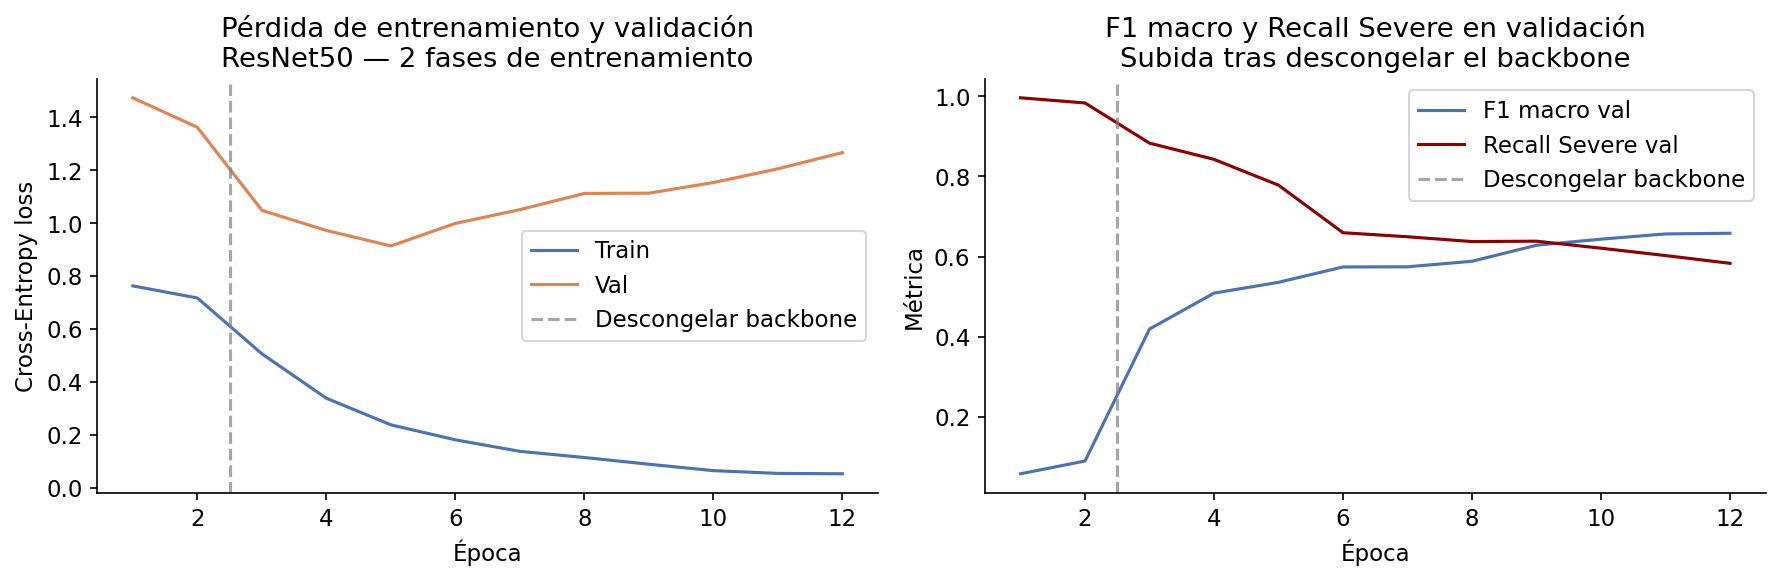

fig_cnn_curvas_entrenamiento.png


In [10]:
# ── Fig 1: Curvas de entrenamiento ──
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs_x = range(1, len(history["train_loss"]) + 1)

ax1.plot(epochs_x, history["train_loss"], label="Train", color="#4C72B0")
ax1.plot(epochs_x, history["val_loss"],   label="Val",   color="#DD8452")
ax1.axvline(x=EPOCHS_FROZEN + 0.5, color="gray", linestyle="--", alpha=0.7, label="Descongelar backbone")
ax1.set_xlabel("Época"); ax1.set_ylabel("Cross-Entropy loss")
ax1.set_title("Pérdida de entrenamiento y validación\nResNet50 — 2 fases de entrenamiento")
ax1.legend()

ax2.plot(epochs_x, history["val_f1"],             label="F1 macro val",     color="#4C72B0")
ax2.plot(epochs_x, history["val_recall_severe"],   label="Recall Severe val", color="#8B0000")
ax2.axvline(x=EPOCHS_FROZEN + 0.5, color="gray", linestyle="--", alpha=0.7, label="Descongelar backbone")
ax2.set_xlabel("Época"); ax2.set_ylabel("Métrica")
ax2.set_title("F1 macro y Recall Severe en validación\nSubida tras descongelar el backbone")
ax2.legend()

sns.despine(); plt.tight_layout()
plt.savefig(FIG / "fig_cnn_curvas_entrenamiento.png", dpi=300, bbox_inches="tight")
plt.show(); print("fig_cnn_curvas_entrenamiento.png")


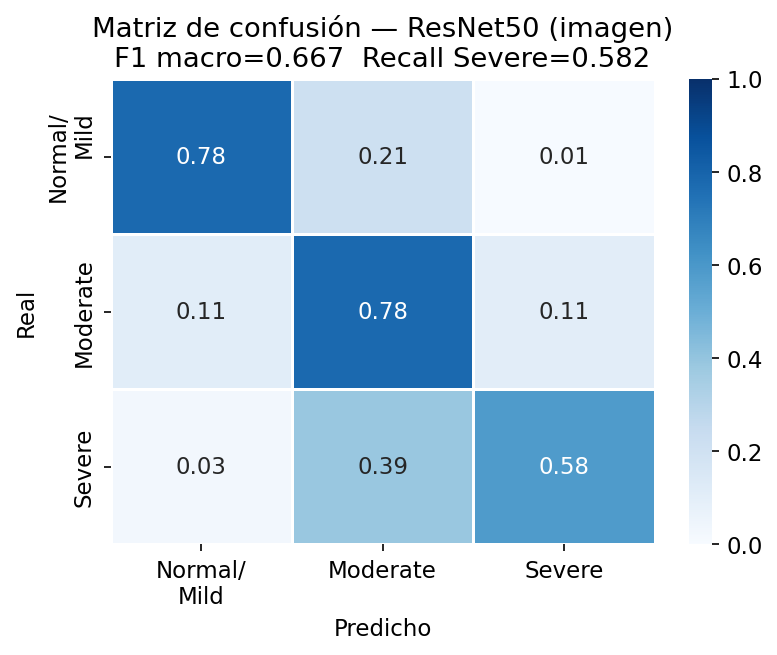

fig_cnn_confusion_matrix.png


In [11]:
# ── Fig 2: Matriz de confusión ResNet50 ──
cm = np.array(res_cnn["confusion_matrix"], dtype=float)
cm_norm = cm / (cm.sum(axis=1, keepdims=True) + 1e-9)
tick_labels = ["Normal/\nMild", "Moderate", "Severe"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f",
            xticklabels=tick_labels, yticklabels=tick_labels,
            cmap="Blues", ax=ax, vmin=0, vmax=1, linewidths=0.5)
ax.set_ylabel("Real"); ax.set_xlabel("Predicho")
ax.set_title(f"Matriz de confusión — ResNet50 (imagen)\nF1 macro={res_cnn['f1_macro']:.3f}  Recall Severe={res_cnn['recall_severe']:.3f}")
plt.tight_layout()
plt.savefig(FIG / "fig_cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show(); print("fig_cnn_confusion_matrix.png")


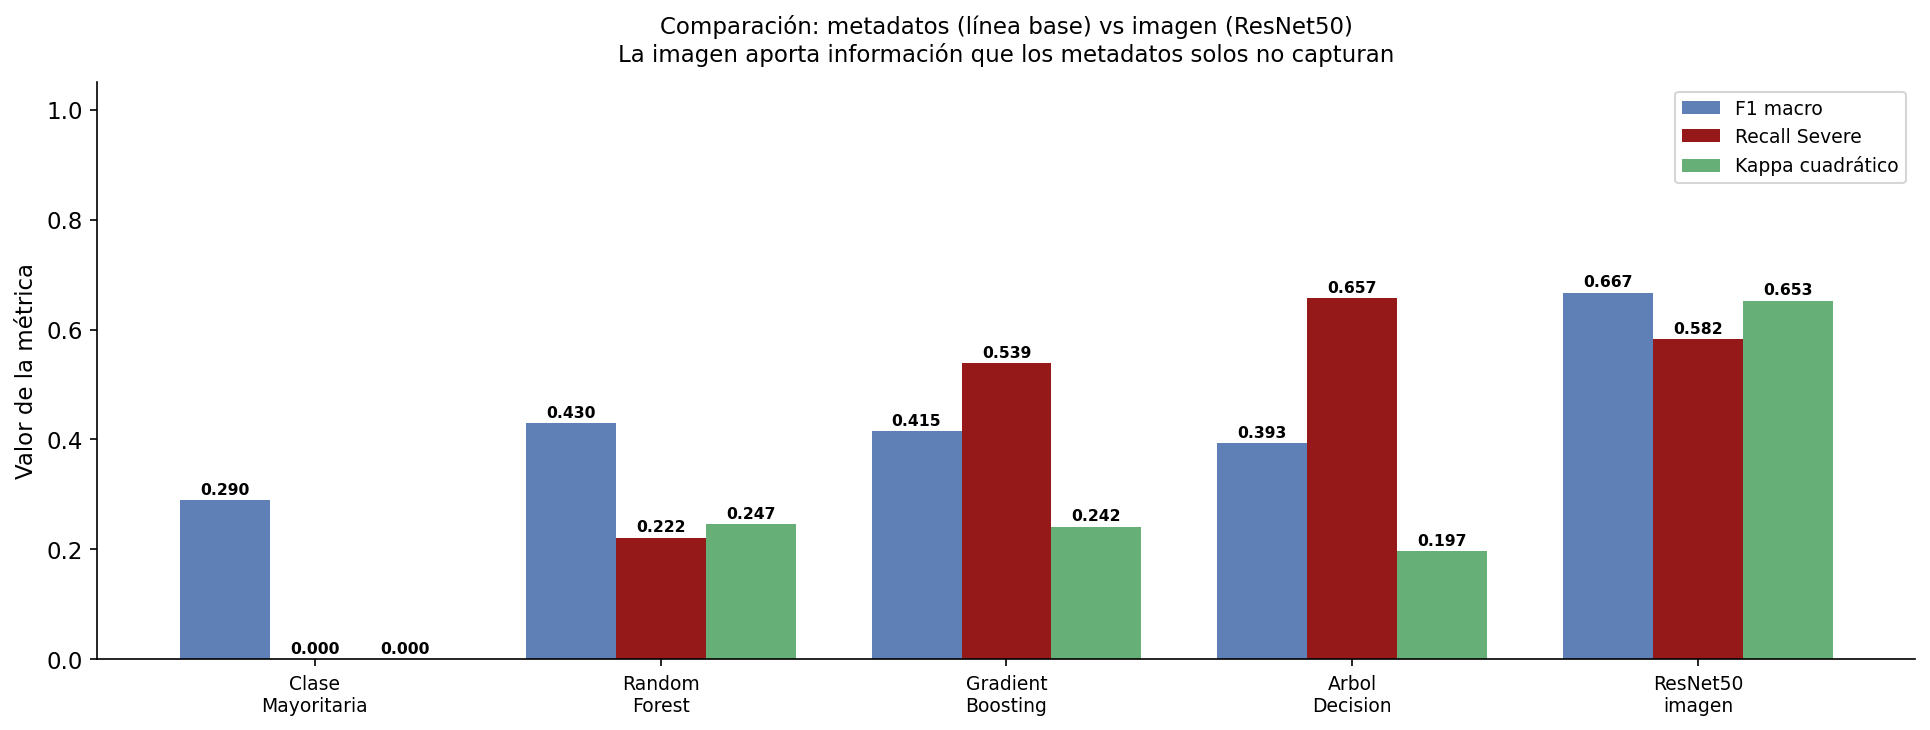

fig_comparacion_todos_modelos.png


In [12]:
# ── Fig 3: Comparación imagen vs metadatos ──
todos_modelos = resultados_final["modelos"]
nombres = [m["modelo"].replace("_", "\n") for m in todos_modelos]
f1s    = [m["f1_macro"]      for m in todos_modelos]
rec_sv = [m["recall_severe"] for m in todos_modelos]
kappas = [m["kappa_quadratic"] for m in todos_modelos]

x = np.arange(len(nombres)); w = 0.26
fig, ax = plt.subplots(figsize=(13, 5))
b1 = ax.bar(x - w, f1s,    w, label="F1 macro",       color="#4C72B0", alpha=0.9)
b2 = ax.bar(x,     rec_sv, w, label="Recall Severe",  color="#8B0000", alpha=0.9)
b3 = ax.bar(x + w, kappas, w, label="Kappa cuadrático", color="#55A868", alpha=0.9)

for bars in [b1, b2, b3]:
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.005, f"{h:.3f}",
                ha="center", va="bottom", fontsize=7.5, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(nombres, fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel("Valor de la métrica")
ax.set_title("Comparación: metadatos (línea base) vs imagen (ResNet50)\n"
             "La imagen aporta información que los metadatos solos no capturan",
             fontsize=11, pad=10)
ax.legend(fontsize=9)
sns.despine(); plt.tight_layout()
plt.savefig(FIG / "fig_comparacion_todos_modelos.png", dpi=300, bbox_inches="tight")
plt.show(); print("fig_comparacion_todos_modelos.png")


## 10. Guardar modelos y figuras

Los archivos en `/kaggle/working/` se guardan automáticamente como output del notebook.
Descárgalos desde el panel **Output** → úsalos en la app local.

In [13]:
print("=== Archivos generados ===")
for f in sorted(WORK.rglob("*")):
    if f.is_file():
        size_kb = f.stat().st_size / 1024
        print(f"  {f.relative_to(WORK)} — {size_kb:.0f} KB")


=== Archivos generados ===
  .virtual_documents/__notebook_source__.ipynb — 25 KB
  entrega_proyecto2.zip — 740 KB
  entrega_proyecto2_completa.zip — 90180 KB
  figures/fig_cnn_confusion_matrix.png — 127 KB
  figures/fig_cnn_curvas_entrenamiento.png — 250 KB
  figures/fig_comparacion_todos_modelos.png — 186 KB
  figures/verificacion_dicom_recorte.png — 270 KB
  models/resnet50_best.pt — 96520 KB
  resultados.json — 3 KB
  splits.csv — 30 KB


In [14]:
!zip -r entrega_proyecto2_completa_v2.zip figures models resultados.json splits.csv


  adding: figures/ (stored 0%)
  adding: figures/fig_comparacion_todos_modelos.png (deflated 24%)
  adding: figures/fig_cnn_curvas_entrenamiento.png (deflated 12%)
  adding: figures/fig_cnn_confusion_matrix.png (deflated 12%)
  adding: figures/verificacion_dicom_recorte.png (deflated 6%)
  adding: models/ (stored 0%)
  adding: models/resnet50_best.pt (deflated 7%)
  adding: resultados.json (deflated 63%)
  adding: splits.csv (deflated 63%)
